# Step 5 - CNN forecast of next-month rainfall anomalies over Senegal

**Question.** From the last three monthly rainfall maps (CHIRPS, 0.05 deg), can a convolutional network
predict the rainfall anomaly map of the following month better than two standard baselines?

* **Climatology** - forecast the 1991-2020 normal of the target month (anomaly = 0)
* **Persistence** - forecast that last month's anomaly continues

**Protocol.** Anomalies are standardised per calendar month and per cell on 1991-2020.
Chronological split, no shuffling across time: train 1991-2014, validation 2015-2018 (early stopping),
test 2019-2025 (never seen during training or model selection). Scores are reported for rainy-season
targets (June-October), the months that matter for farming decisions.

**Expected result, stated before running.** Monthly rainfall in the Sahel is driven largely by ocean
temperatures and the West African monsoon, which are not in these inputs. A modest skill, or none,
is a legitimate finding; this notebook reports whatever the test set says.

In [1]:
!pip -q install tifffile
import gzip, io, os, numpy as np, requests, tifffile, torch, torch.nn as nn
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"; print(device)

cuda


In [2]:
# Senegal CHIRPS cube: taken from the repository if present, otherwise rebuilt by streaming
# (each African map is downloaded in memory, cropped to Senegal, then discarded).
CUBE = "chirps_monthly_senegal.npz"
REPO = "https://raw.githubusercontent.com/diaselma/senegal-agroclimate/main/data/processed/" + CUBE
if not os.path.exists(CUBE):
    r = requests.get(REPO, timeout=120)
    if r.ok: open(CUBE, "wb").write(r.content)
if not os.path.exists(CUBE):
    URL = "https://data.chc.ucsb.edu/products/CHIRPS-2.0/africa_monthly/tifs/chirps-v2.0.{y}.{m:02d}.tif.gz"
    rows, cols = slice(460, 560), slice(43, 176)          # 17N-12N, 17.8W-11.2W
    def fetch(ym):
        g = tifffile.imread(io.BytesIO(gzip.decompress(requests.get(URL.format(y=ym[0], m=ym[1]), timeout=120).content)))[rows, cols]
        return np.where(g < 0, np.nan, g).astype("float32")
    months = [(y, m) for y in range(1991, 2026) for m in range(1, 13)]
    with ThreadPoolExecutor(8) as p: rain = np.stack(list(p.map(fetch, months)))
    np.savez_compressed(CUBE, rain=rain, time=np.array([f"{y}-{m:02d}" for y, m in months]))
d = np.load(CUBE); rain = d["rain"]; time = d["time"]
years = np.array([int(t[:4]) for t in time]); months = np.array([int(t[5:]) for t in time])
land = np.isfinite(rain).all(0); print(rain.shape, f"land cells: {land.sum()}")

(420, 100, 133) land cells: 11190


In [3]:
# standardised anomalies per calendar month and cell, on the 1991-2020 normal
ref = (years >= 1991) & (years <= 2020)
r = np.nan_to_num(np.log1p(rain))                         # log1p tames the skewed rainfall distribution
mu = np.stack([r[ref & (months == m)].mean(0) for m in range(1, 13)])
sd = np.stack([r[ref & (months == m)].std(0) for m in range(1, 13)]) + 0.05
anom = (r - mu[months - 1]) / sd[months - 1]
anom[:, ~land] = 0

def sample(t):                                             # inputs: months t-3..t-1 + target-month encoding
    m = months[t]
    enc = np.ones((2,) + anom.shape[1:], "float32") * np.array([np.sin(2*np.pi*m/12), np.cos(2*np.pi*m/12)])[:, None, None]
    return np.concatenate([anom[t-3:t], enc]).astype("float32"), anom[t:t+1].astype("float32")

idx = np.arange(3, len(time))
split = {"train": idx[years[idx] <= 2014], "val": idx[(years[idx] >= 2015) & (years[idx] <= 2018)],
         "test": idx[years[idx] >= 2019]}
X = {k: torch.tensor(np.stack([sample(t)[0] for t in v])) for k, v in split.items()}
Y = {k: torch.tensor(np.stack([sample(t)[1] for t in v])) for k, v in split.items()}
mask = torch.tensor(land, dtype=torch.float32)
print({k: tuple(v.shape) for k, v in X.items()})

{'train': (285, 5, 100, 133), 'val': (48, 5, 100, 133), 'test': (84, 5, 100, 133)}


In [4]:
class Net(nn.Module):                                      # small encoder-decoder; ~400 training maps only
    def __init__(self, c=32, p=0.2):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU())
        self.enc1, self.enc2 = blk(5, c), nn.Sequential(nn.MaxPool2d(2), blk(c, 2*c), nn.Dropout2d(p))
        self.dec = nn.Sequential(blk(3*c, c), nn.Conv2d(c, 1, 1))
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = nn.functional.interpolate(self.enc2(e1), size=e1.shape[-2:], mode="bilinear", align_corners=False)
        return self.dec(torch.cat([e1, e2], 1))

def mse(pred, y): return (((pred - y) ** 2) * mask.to(y.device)).sum() / (mask.sum() * len(y))

model = Net().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
best, wait, hist = 1e9, 0, []
for epoch in range(300):
    model.train(); perm = torch.randperm(len(X["train"]))
    for b in perm.split(32):
        x, y = X["train"][b].to(device), Y["train"][b].to(device)
        opt.zero_grad(); loss = mse(model(x), y); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad(): v = mse(model(X["val"].to(device)), Y["val"].to(device)).item()
    hist.append(v)
    if v < best: best, wait, state = v, 0, {k: t.clone() for k, t in model.state_dict().items()}
    else:
        wait += 1
        if wait == 25: break
model.load_state_dict(state); print(f"stopped at epoch {epoch}, best validation MSE {best:.3f}")

stopped at epoch 26, best validation MSE 0.556


In [5]:
# test set, rainy-season targets only (June-October)
t_idx = split["test"]; rs = np.isin(months[t_idx], [6, 7, 8, 9, 10])
with torch.no_grad(): cnn = model(X["test"].to(device)).cpu().numpy()[:, 0]
obs = Y["test"].numpy()[:, 0]
fc = {"Climatology": np.zeros_like(obs), "Persistence": X["test"].numpy()[:, 2], "CNN": cnn}

def to_mm(a, t): return np.expm1(a * sd[months[t] - 1] + mu[months[t] - 1])

rows = []
for name, f in fc.items():
    f, o, tt = f[rs], obs[rs], t_idx[rs]
    rmse = np.sqrt(((f - o) ** 2)[:, land].mean())
    rmse_mm = np.sqrt(np.mean([((to_mm(f[i], t) - to_mm(o[i], t)) ** 2)[land].mean() for i, t in enumerate(tt)]))
    acc = np.mean([np.corrcoef(f[i][land], o[i][land])[0, 1] if f[i][land].std() > 0 else 0 for i in range(len(f))])
    rows.append((name, rmse, rmse_mm, acc))
clim = rows[0][1]
print(f"{'forecast':<12}{'RMSE (std anom)':>16}{'RMSE (mm)':>11}{'skill vs clim':>15}{'spatial corr':>14}")
for name, a, b, c in rows:
    print(f"{name:<12}{a:>16.3f}{b:>11.1f}{1 - a**2 / clim**2:>15.1%}{c:>14.2f}")

forecast     RMSE (std anom)  RMSE (mm)  skill vs clim  spatial corr
Climatology            0.899       50.1           0.0%          0.00
Persistence            1.358     2152.3        -128.2%          0.00
CNN                    0.911       50.4          -2.7%          0.04


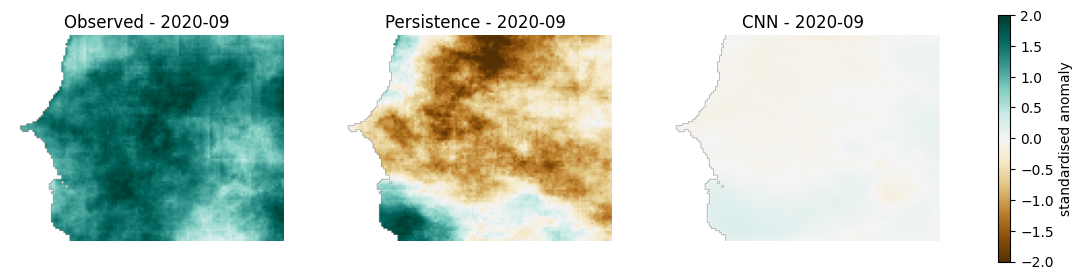

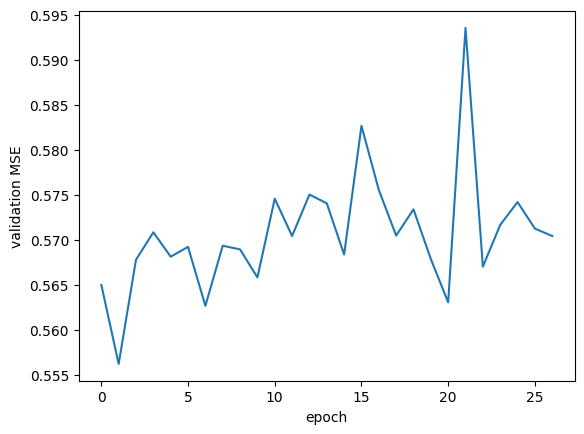

In [6]:
# one example: the test month with the largest observed anomaly
k = np.argmax(np.abs(obs[rs]).mean((1, 2))); t = t_idx[rs][k]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (title, img) in zip(ax, [("Observed", obs[rs][k]), ("Persistence", fc["Persistence"][rs][k]), ("CNN", cnn[rs][k])]):
    im = a.imshow(np.where(land, img, np.nan), cmap="BrBG", vmin=-2, vmax=2); a.set_title(f"{title} - {time[t]}"); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.8, label="standardised anomaly"); plt.show()
plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("validation MSE"); plt.show()

## Reading the result

* **Skill vs climatology** = 1 - MSE(model) / MSE(climatology). Positive means the forecast adds
  information over the normal; zero or negative means it does not.
* Whatever the CNN scores, the operational lesson is the same: a useful monthly forecast for Senegal
  needs large-scale drivers (Atlantic and Pacific sea-surface temperatures, monsoon indices) as inputs.
  Adding them, and benchmarking against ECMWF SEAS5 or the PRESASS consensus forecasts, is the next step.